In [1]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os

In [17]:
def read_files(glob_pattern, minyear=0, maxyear=999):
    files = glob.glob(glob_pattern)
    open_areas = []
    for fname in tqdm(files):
        year = int(os.path.basename(fname)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue
            
        hdf = h5py.File(fname)
        
        if 'open_fraction_by_sample' in hdf.keys():
            open_areas.append(hdf['open_fraction_by_sample'][()].item())
        elif 'open_fraction_by_realization' in hdf.keys():
            open_areas.append(hdf['open_fraction_by_realization'][0])
        elif 'open_fraction' in hdf.keys():
            open_areas.append(hdf['open_fraction'][()].item())

    return open_areas

In [10]:
open_areas_samples = read_files('../data/validation/open_area_truncated/*.hdf5', maxyear=2020)

100%|███████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 3285.65it/s]


In [18]:
open_areas_testdata = read_files('../data/validation/open_area_testdata/*.hdf5', maxyear=2020)

100%|███████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 3747.17it/s]


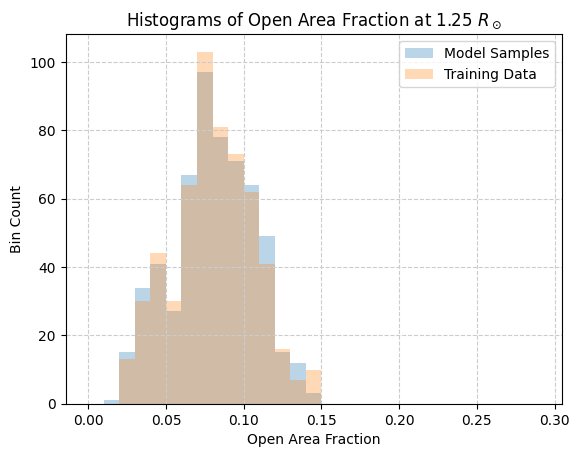

In [19]:
bins = np.arange(0, .3, .01)


plt.hist(open_areas_samples, bins=bins, label='Model Samples', alpha=0.3)
plt.hist(open_areas_testdata, bins=bins, label='Training Data', alpha=0.3)

plt.legend()
plt.ylabel('Bin Count')
plt.xlabel('Open Area Fraction')
plt.title(r'Histograms of Open Area Fraction at 1.25 $R_\odot$')
plt.grid(linestyle='dashed', color='#ccc')